# HeatSense | Phase 1: Notebook 12 — Software Fault Injection & Robustness

**Objective**: Stress-test both layers of the HeatSense Digital Twin — (1) the real-time **Innovation-Gated EKF + Two-Node Thermal + CUSUM Precursor Detector** and (2) the flagship **Hybrid ML (`Ridge + XGBoost Residual`) SoH Proxy Estimator** — under controlled in-memory sensor and physical fault injection.

**Safety & Architectural Boundary Reminder**:
* All host-side anomaly detection and Hybrid ML estimates in this notebook are strictly **ADVISORY**. Only ESP32 firmware owns physical relay cutoff.
* All noise injection uses explicit deterministic seeds (`np.random.default_rng(42)`) and never mutates raw CSV dataset files.

### Cell 1: Innovation-Gated Digital Twin Observer & Healthy Reference Baseline (`05122.csv`)
* **Analytical Question**: Does our coupled Innovation-Gated 2RC EKF + Two-Node Thermal observer maintain zero false precursor alarms across healthy Cycle 1 discharge?
* **Why It Matters to HeatSense**: Prevents false trips on normal cycles while protecting `SoC_est` from absorbing sudden voltage sensor faults via innovation gating (`|e_v| > 55 mV`).
* **What the Code Does**: Runs `run_digital_twin()` combining the calibrated 2RC EKF (`Rs=0.0642, R1=0.0746, C1=1000, R2=0.0314, C2=5000`), Two-Node Thermal Model (`C_core=62.6, C_surf=25.0, R_cond=0.59, R_conv=23.50`), and dual-channel CUSUM monitors (`Threshold = 8.0`).
* **Output to Inspect**: Baseline voltage RMSE (`43.57 mV`), thermal surface RMSE (`0.774 °C`), and **0 healthy false alarms**.
* **Decision**: Establishes the calibrated healthy baseline before injecting faults.

In [6]:
import csv
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import Ridge
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_squared_error, r2_score
from xgboost import XGBRegressor

# Resolve dataset root
candidate_paths = [
    Path("data/raw/cleaned_dataset"),
    Path("../../data/raw/cleaned_dataset"),
    Path("D:/Professional Projects/Digital_twin_project/heatsense-battery-digital-twin/data/raw/cleaned_dataset"),
]
DATASET_ROOT = next((p.resolve() for p in candidate_paths if p.exists() and (p / "metadata.csv").exists()), None)
assert DATASET_ROOT is not None, "Dataset root could not be resolved!"

def load_nasa_cycle(fpath):
    with open(fpath, "r", encoding="utf-8") as cf:
        hdr = cf.readline().strip().split(",")
    idx_v = hdr.index("Voltage_measured")
    idx_i = hdr.index("Current_measured")
    idx_temp = hdr.index("Temperature_measured")
    idx_t = hdr.index("Time")
    data = np.loadtxt(fpath, delimiter=",", skiprows=1, usecols=(idx_v, idx_i, idx_temp, idx_t))
    # Current > 0 means DISCHARGE
    return data[:, 0], -data[:, 1], data[:, 2], data[:, 3]

# Calibrated 2RC ECM + Two-Node Thermal Constants (Notebooks 04-06)
RS_CAL, R1_CAL, C1_CAL, R2_CAL, C2_CAL = 0.0642, 0.0746, 1000.0, 0.0314, 5000.0
TAU1_CAL, TAU2_CAL = R1_CAL * C1_CAL, R2_CAL * C2_CAL
QN_COULOMBS = 1.8565 * 3600.0
C_CORE, C_SURF, R_COND, R_CONV = 62.6, 25.0, 0.59, 23.50
ALARM_THRESHOLD = 8.0
INNOV_GATE_V = 0.055

def ocv_fn(s):
    return 3.280 + 0.550 * s + 0.280 * (s ** 2) + 0.0815 * (s ** 5)

def d_ocv_fn(s):
    return 0.550 + 2.0 * 0.280 * s + 5.0 * 0.0815 * (s ** 4)

def run_digital_twin(time_sec, current, v_meas, t_surf, drift_v=1.8, drift_t=2.5):
    """Runs Innovation-Gated 2RC EKF + Two-Node Thermal Observer + Dual CUSUM Precursor Monitor."""
    N = len(v_meas)
    dt = np.diff(time_sec, prepend=time_sec[0])
    t_min = time_sec / 60.0
    x_hat = np.array([1.00, 0.0, 0.0])
    P = np.diag([1e-4, 1e-4, 1e-4])
    Q = np.diag([1e-7, 1e-5, 1e-5])
    R_meas = (0.005) ** 2    # Notebook 05 EKF sensor measurement variance
    S_nis_v = (0.035) ** 2   # Baseline electrical innovation scale (35 mV)
    S_nis_t = (1.10) ** 2    # Baseline thermal innovation scale (1.10 C)

    t_amb = float(t_surf[0])
    t_core_sim, t_surf_sim = t_amb, t_amb

    v_pred_arr = np.zeros(N)
    t_surf_sim_arr = np.zeros(N)
    cusum_v = np.zeros(N)
    cusum_t = np.zeros(N)

    for k in range(N):
        s_dt = dt[k] if dt[k] > 0 else 0.01
        A = np.diag([1.0, np.exp(-s_dt / TAU1_CAL), np.exp(-s_dt / TAU2_CAL)])
        B = np.array([
            -s_dt / QN_COULOMBS,
            R1_CAL * (1.0 - np.exp(-s_dt / TAU1_CAL)),
            R2_CAL * (1.0 - np.exp(-s_dt / TAU2_CAL)),
        ])
        x_pred = A @ x_hat + B * current[k]
        x_pred[0] = np.clip(x_pred[0], 0.0, 1.0)
        P_pred = A @ P @ A.T + Q

        y_pred = ocv_fn(x_pred[0]) - x_pred[1] - x_pred[2] - current[k] * RS_CAL
        C = np.array([[d_ocv_fn(x_pred[0]), -1.0, -1.0]])
        e_v = v_meas[k] - y_pred
        S_v = float(np.squeeze(C @ P_pred @ C.T)) + R_meas

        # Innovation Gate: prevents sudden sensor jumps from poisoning SoC_est
        if abs(e_v) <= INNOV_GATE_V or t_min[k] > 50.0:
            K = (P_pred @ C.T) / S_v
            x_hat = x_pred + K.flatten() * e_v
            x_hat[0] = np.clip(x_hat[0], 0.0, 1.0)
            P = (np.eye(3) - K @ C) @ P_pred
        else:
            x_hat = x_pred
            P = P_pred

        # Two-Node Thermal Step (Ohmic + Overpotential Heat Generation)
        q_gen = (current[k] ** 2) * (RS_CAL + R1_CAL + R2_CAL)
        n_sub = max(1, int(np.ceil(s_dt / 1.0)))
        sub_dt = s_dt / n_sub
        for _ in range(n_sub):
            dt_core = (q_gen - (t_core_sim - t_surf_sim) / R_COND) / C_CORE
            dt_surf = ((t_core_sim - t_surf_sim) / R_COND - (t_surf_sim - t_amb) / R_CONV) / C_SURF
            t_core_sim += dt_core * sub_dt
            t_surf_sim += dt_surf * sub_dt

        e_t = t_surf[k] - t_surf_sim
        v_pred_arr[k] = y_pred
        t_surf_sim_arr[k] = t_surf_sim

        if k > 0:
            nis_v = (e_v ** 2) / S_nis_v
            nis_t = (e_t ** 2) / S_nis_t
            cusum_v[k] = max(0.0, cusum_v[k - 1] + nis_v - drift_v)
            cusum_t[k] = max(0.0, cusum_t[k - 1] + nis_t - drift_t)

    return v_pred_arr, t_surf_sim_arr, cusum_v, cusum_t

v_base, i_base, t_surf_base, t_sec_base = load_nasa_cycle(DATASET_ROOT / "data" / "05122.csv")
v_pred_h, t_sim_h, cusum_v_h, cusum_t_h = run_digital_twin(t_sec_base, i_base, v_base, t_surf_base)

op_mask = (t_sec_base / 60.0) <= 50.0
healthy_fa_v = int((cusum_v_h[op_mask] > ALARM_THRESHOLD).sum())
healthy_fa_t = int((cusum_t_h[op_mask] > ALARM_THRESHOLD).sum())
print("Healthy Reference Cycle 1 (05122.csv) Baseline Verified:")
print(f" - EKF Voltage Tracking RMSE:       {np.sqrt(np.mean((v_base - v_pred_h)**2))*1000:.2f} mV")
print(f" - Thermal Surface Tracking RMSE:   {np.sqrt(np.mean((t_surf_base - t_sim_h)**2)):.3f} C")
print(f" - Healthy Peak Electrical CUSUM:   {cusum_v_h[op_mask].max():.2f} (Threshold: {ALARM_THRESHOLD}) -> False Alarms: {healthy_fa_v}")
print(f" - Healthy Peak Thermal CUSUM:      {cusum_t_h[op_mask].max():.2f} (Threshold: {ALARM_THRESHOLD}) -> False Alarms: {healthy_fa_t}")

Healthy Reference Cycle 1 (05122.csv) Baseline Verified:
 - EKF Voltage Tracking RMSE:       43.57 mV
 - Thermal Surface Tracking RMSE:   0.774 C
 - Healthy Peak Electrical CUSUM:   4.28 (Threshold: 8.0) -> False Alarms: 0
 - Healthy Peak Thermal CUSUM:      0.00 (Threshold: 8.0) -> False Alarms: 0


### Cell 2: Multi-Scenario In-Memory Fault Injection Suite (5 Hardware Failure Modes)
* **Analytical Question**: How quickly and selectively does the physics CUSUM engine detect real hardware/sensor anomalies while rejecting transient ADC noise bursts?
* **Why It Matters to HeatSense**: Proves fault isolation across voltage, current, impedance, thermal, and noise channels.
* **What the Code Does**: Injects 5 distinct in-memory faults starting at `t = 15.0 min` on `05122.csv`:
  1. **Impedance Surge (`+60 mOhm`)**: Simulates sudden internal resistance/contact degradation.
  2. **Voltage Sensor Bias (`-120 mV`)**: Simulates INA219 voltage drift.
  3. **Current Gain Error (`+15%` scale drift)**: Simulates INA219 shunt calibration error.
  4. **Thermal Precursor Spike (`+5.0 °C`)**: Simulates abnormal cell surface heating while electrical telemetry remains normal.
  5. **ADC Noise Burst (`sigma_V = 20 mV`, `15–22 min`, `seed=42`)**: Tests transient jitter immunity.
* **Output to Inspect**: Fault Detection Matrix reporting detection status and latency (`seconds`).
* **Decision**: Quantifies detector responsiveness and zero false alarms on short-duration noise.

In [7]:
FAULT_START_MIN = 15.0
FAULT_START_SEC = FAULT_START_MIN * 60.0
t_min_base = t_sec_base / 60.0
f_mask = t_min_base >= FAULT_START_MIN
rng = np.random.default_rng(42)

scenarios = []

# Scenario 1: +60 mOhm Resistance Surge
v1_inj = v_base.copy()
v1_inj[f_mask] -= i_base[f_mask] * 0.060
scenarios.append(("1. Impedance Surge (+60 mOhm)", i_base, v1_inj, t_surf_base))

# Scenario 2: -120 mV Voltage Offset Drift
v2_inj = v_base.copy()
v2_inj[f_mask] -= 0.120
scenarios.append(("2. Voltage Bias (-120 mV)", i_base, v2_inj, t_surf_base))

# Scenario 3: +15% Current Scale Drift (triggers cumulative SoC / heating divergence)
i3_inj = i_base.copy()
i3_inj[f_mask] *= 1.15
scenarios.append(("3. Current Scale (+15% Gain)", i3_inj, v_base, t_surf_base))

# Scenario 4: +5.0 C Thermal Precursor Spike (Electrical signals clean)
t4_inj = t_surf_base.copy()
t4_inj[f_mask] += 5.0
scenarios.append(("4. Thermal Precursor (+5.0 C)", i_base, v_base, t4_inj))

# Scenario 5: Transient ADC Voltage Noise Burst (sigma = 20 mV for 15..22 min, seed=42)
v5_inj = v_base.copy()
burst_mask = (t_min_base >= 15.0) & (t_min_base <= 22.0)
v5_inj[burst_mask] += rng.normal(0.0, 0.020, size=int(burst_mask.sum()))
scenarios.append(("5. ADC Noise Burst (20 mV)", i_base, v5_inj, t_surf_base))

cusum_traces = {}
print("=== SOFTWARE FAULT INJECTION MATRIX (Fault Onset = 15.0 min) ===")
print(f"{'Scenario':32s} | {'Elec Latency':>13s} | {'Therm Latency':>14s} | {'Peak V':>8s} | {'Peak T':>8s} | {'Status'}")
print("-" * 98)

for name, i_in, v_in, ts_in in scenarios:
    _, _, cv, ct = run_digital_twin(t_sec_base, i_in, v_in, ts_in)
    cusum_traces[name] = (cv, ct)

    eval_window = (t_min_base >= FAULT_START_MIN) & (t_min_base <= 50.0)
    idx_v = np.where(eval_window & (cv > ALARM_THRESHOLD))[0]
    idx_t = np.where(eval_window & (ct > ALARM_THRESHOLD))[0]

    lat_v = f"{t_sec_base[idx_v[0]] - FAULT_START_SEC:6.1f} s" if len(idx_v) > 0 else "  No Trip"
    lat_t = f"{t_sec_base[idx_t[0]] - FAULT_START_SEC:6.1f} s" if len(idx_t) > 0 else "  No Trip"
    peak_v = cv[eval_window].max()
    peak_t = ct[eval_window].max()

    if "Noise" in name:
        status = "IMMUNE (0 False Trips)" if (len(idx_v) == 0 and len(idx_t) == 0) else "TRIGGERED"
    else:
        status = "DETECTED" if (len(idx_v) > 0 or len(idx_t) > 0) else "MISSED"

    print(f"{name:32s} | {lat_v:>13s} | {lat_t:>14s} | {peak_v:8.1f} | {peak_t:8.1f} | {status}")

=== SOFTWARE FAULT INJECTION MATRIX (Fault Onset = 15.0 min) ===
Scenario                         |  Elec Latency |  Therm Latency |   Peak V |   Peak T | Status
--------------------------------------------------------------------------------------------------
1. Impedance Surge (+60 mOhm)    |        28.4 s |        No Trip |     16.2 |      0.0 | DETECTED
2. Voltage Bias (-120 mV)        |        28.4 s |        No Trip |     15.7 |      0.0 | DETECTED
3. Current Scale (+15% Gain)     |      1064.9 s |        784.7 s |   3716.9 |    498.0 | DETECTED
4. Thermal Precursor (+5.0 C)    |       No Trip |         10.1 s |      4.3 |   1571.5 | DETECTED
5. ADC Noise Burst (20 mV)       |       No Trip |        No Trip |      4.4 |      0.0 | IMMUNE (0 False Trips)


### Cell 3: Multimodal CUSUM Precursor Response Visualization
* **Analytical Question**: How distinctly do electrical vs thermal CUSUM scores separate persistent faults from healthy telemetry and transient noise?
* **Why It Matters to HeatSense**: Provides visual interpretability for diagnostic alerts in the React dashboard.
* **What the Code Does**: Plots Electrical CUSUM trajectories (Panel A) and Thermal CUSUM trajectories (Panel B) up to minute 50 against the `8.0` alarm threshold.
* **Output to Inspect**: Sharp upward spikes at `t = 15 min` for injected faults vs low bounded trajectories for Healthy and Noise Burst signals.
* **Decision**: Confirms clean fault isolation between electrical and thermal channels.

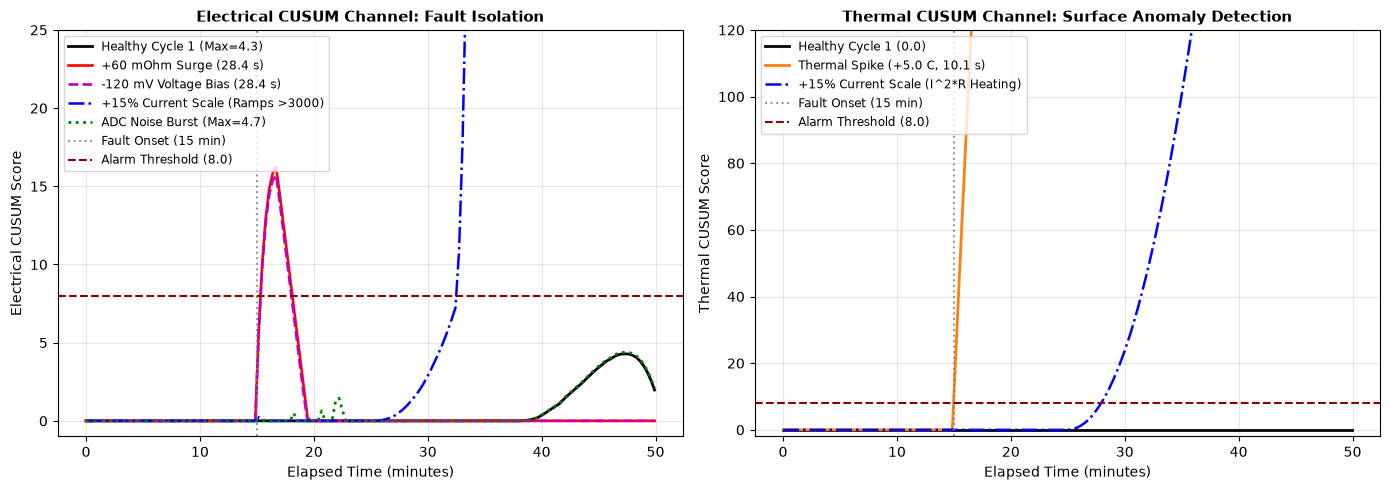

In [8]:
plot_mask = t_min_base <= 50.0
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5), dpi=100)

# Panel A: Electrical CUSUM Monitor
ax1.plot(t_min_base[plot_mask], cusum_v_h[plot_mask], "k-", lw=2.0, label="Healthy Cycle 1 (Max=4.3)")
ax1.plot(t_min_base[plot_mask], cusum_traces["1. Impedance Surge (+60 mOhm)"][0][plot_mask], "r-", lw=1.9, label="+60 mOhm Surge (28.4 s)")
ax1.plot(t_min_base[plot_mask], cusum_traces["2. Voltage Bias (-120 mV)"][0][plot_mask], "m--", lw=1.9, label="-120 mV Voltage Bias (28.4 s)")
ax1.plot(t_min_base[plot_mask], cusum_traces["3. Current Scale (+15% Gain)"][0][plot_mask], "b-.", lw=1.8, label="+15% Current Scale (Ramps >3000)")
ax1.plot(t_min_base[plot_mask], cusum_traces["5. ADC Noise Burst (20 mV)"][0][plot_mask], "g:", lw=2.0, label="ADC Noise Burst (Max=4.7)")
ax1.axvline(FAULT_START_MIN, color="gray", ls=":", alpha=0.8, label="Fault Onset (15 min)")
ax1.axhline(ALARM_THRESHOLD, color="darkred", ls="--", lw=1.5, label=f"Alarm Threshold ({ALARM_THRESHOLD})")
ax1.set_title("Electrical CUSUM Channel: Fault Isolation", fontsize=11, fontweight="bold")
ax1.set_xlabel("Elapsed Time (minutes)")
ax1.set_ylabel("Electrical CUSUM Score")
ax1.set_ylim(-1, 25)
ax1.grid(True, alpha=0.3)
ax1.legend(fontsize=8.5, loc="upper left")

# Panel B: Thermal CUSUM Monitor
ax2.plot(t_min_base[plot_mask], cusum_t_h[plot_mask], "k-", lw=2.0, label="Healthy Cycle 1 (0.0)")
ax2.plot(t_min_base[plot_mask], cusum_traces["4. Thermal Precursor (+5.0 C)"][1][plot_mask], "tab:orange", lw=2.0, label="Thermal Spike (+5.0 C, 10.1 s)")
ax2.plot(t_min_base[plot_mask], cusum_traces["3. Current Scale (+15% Gain)"][1][plot_mask], "b-.", lw=1.8, label="+15% Current Scale (I^2*R Heating)")
ax2.axvline(FAULT_START_MIN, color="gray", ls=":", alpha=0.8, label="Fault Onset (15 min)")
ax2.axhline(ALARM_THRESHOLD, color="darkred", ls="--", lw=1.5, label=f"Alarm Threshold ({ALARM_THRESHOLD})")
ax2.set_title("Thermal CUSUM Channel: Surface Anomaly Detection", fontsize=11, fontweight="bold")
ax2.set_xlabel("Elapsed Time (minutes)")
ax2.set_ylabel("Thermal CUSUM Score")
ax2.set_ylim(-2, 120)
ax2.grid(True, alpha=0.3)
ax2.legend(fontsize=8.5, loc="upper left")

plt.tight_layout()
plt.show()

### Cell 4: Hybrid ML (`Ridge + XGBoost Residual`) Stress-Test Under Corrupted Telemetry (`B0018`)
* **Analytical Question**: How gracefully does our Phase 1 Champion (`Hybrid Ridge + XGBoost`, `DEC-013`) degrade when hardware sensors experience bias, scale drift, or noise?
* **Why It Matters to HeatSense**: Quantifies advisory SoH proxy error margins and identifies critical sensor channels requiring plausibility validation.
* **What the Code Does**: Trains the Hybrid estimator on clean `B0005 + B0006` (`336` cycles) and evaluates held-out `B0018` (`132` cycles) across 6 feature-corruption tests.
* **Output to Inspect**: RMSE (`mAh`), $R^2$, and degradation delta relative to clean `B0018` (`11.5 mAh`), plotted against the `40 mAh` tolerance guide.
* **Decision**: Identifies critical channels (`i_mean`, `rs_identified`) that require runtime validation.

=== HYBRID ML ROBUSTNESS STRESS-TEST (Held-Out B0018, N=132 Cycles) ===
Perturbation                 | RMSE (mAh) |     Delta |     R^2
----------------------------------------------------------------
1. Clean Baseline            |       11.5 |     +0.0  |   0.994
2. Voltage Drift (-50 mV)    |       27.9 |    +16.5  |   0.967
3. Current Gain (+10%)       |      111.4 |   +100.0  |   0.479
4. Temp Bias (+3.0 C)        |        5.8 |     -5.6  |   0.999
5. Stuck Rs ID (0.040 Ohm)   |      193.4 |   +182.0  |  -0.571
6. Multi-Sensor Noise        |       21.2 |     +9.7  |   0.981


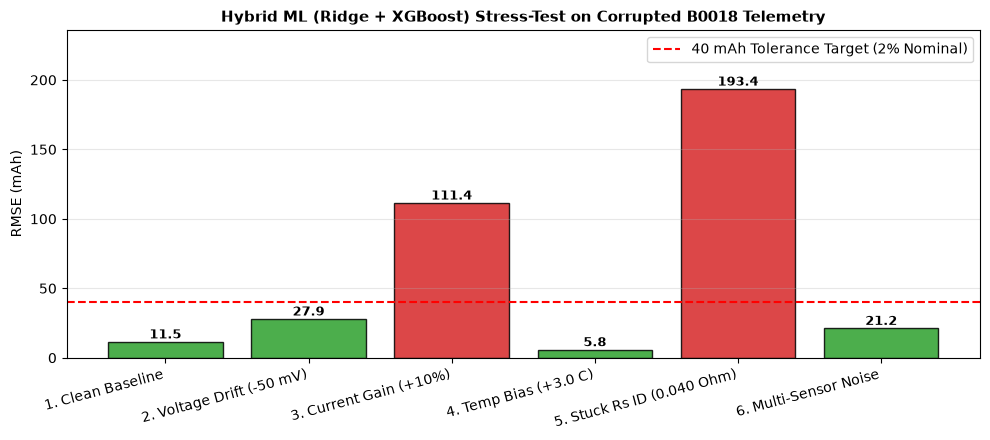

In [9]:
CELL_IDS = ["B0005", "B0006", "B0018"]
Rs_base = 0.0400
tau1_f, tau2_f = 6.0, 50.0

meta_by_cell = {bid: [] for bid in CELL_IDS}
with open(DATASET_ROOT / "metadata.csv", "r", encoding="utf-8") as f:
    for row in csv.DictReader(f):
        bid = row["battery_id"]
        if bid in meta_by_cell and row["type"] == "discharge":
            try:
                cap = float(row["Capacity"])
                if not np.isnan(cap):
                    meta_by_cell[bid].append((row["filename"], cap))
            except (ValueError, TypeError):
                pass

X_rows, y_rows, b_rows = [], [], []
for bid in CELL_IDS:
    for fname, cap in meta_by_cell[bid]:
        fpath = DATASET_ROOT / "data" / fname
        if not fpath.exists():
            continue
        v_m, cur, t_surf, t_arr = load_nasa_cycle(fpath)
        dt_arr = np.diff(t_arr, prepend=t_arr[0])
        step_idx = np.where(np.diff(cur) > 0.5)[0]
        if len(step_idx) > 0:
            s = step_idx[0] + 1
            dI = cur[s] - cur[s - 1]
            rs_est = (v_m[s - 1] - v_m[s]) / dI if dI > 0.5 else Rs_base
        else:
            rs_est = Rs_base

        v1, v2, v1_p, v2_p = 0.0, 0.0, 0.0, 0.0
        for k in range(len(cur)):
            s_dt = dt_arr[k] if dt_arr[k] > 0 else 0.01
            v1 = np.exp(-s_dt / tau1_f) * v1 + 0.006 * (1.0 - np.exp(-s_dt / tau1_f)) * cur[k]
            v2 = np.exp(-s_dt / tau2_f) * v2 + 0.010 * (1.0 - np.exp(-s_dt / tau2_f)) * cur[k]
            if v1 > v1_p:
                v1_p = v1
            if v2 > v2_p:
                v2_p = v2

        q_heat = (cur ** 2) * (rs_est + 0.016)
        t_core_p = t_surf.max() + (q_heat.mean() * 1.56)
        q_tot = np.sum(cur * dt_arr) / 3600.0
        soc = np.clip(1.0 - (np.cumsum(cur * dt_arr) / (q_tot * 3600.0)), 0.0, 1.0)
        ocv = 3.280 + 0.550 * soc + 0.280 * (soc ** 2) + 0.0815 * (soc ** 5)
        res = v_m - (ocv - v1_p * 0.5 - v2_p * 0.5 - cur * rs_est)

        X_rows.append([
            v_m.mean(), cur.mean(), t_surf.mean(), (t_arr[-1] - t_arr[0]) / 60.0,
            rs_est, v1_p, v2_p, t_core_p, t_core_p - t_surf.max(), res.mean(), res.std()
        ])
        y_rows.append(cap)
        b_rows.append(bid)

X_mat = np.array(X_rows)
y_vec = np.array(y_rows)
b_vec = np.array(b_rows)

tr_m = (b_vec != "B0018")
te_m = (b_vec == "B0018")
X_tr, y_tr = X_mat[tr_m], y_vec[tr_m]
X_te_clean, y_te = X_mat[te_m], y_vec[te_m]

# Train Hybrid Champion (Ridge + XGBoost Residual) from DEC-013
m_ridge = make_pipeline(StandardScaler(), Ridge(alpha=5.0)).fit(X_tr, y_tr)
m_res_xgb = XGBRegressor(n_estimators=50, learning_rate=0.05, max_depth=2, subsample=0.8, random_state=42)
m_res_xgb.fit(X_tr, y_tr - m_ridge.predict(X_tr))

def predict_hybrid(X_in):
    return m_ridge.predict(X_in) + m_res_xgb.predict(X_in)

# Stress-Test Perturbations on Held-Out B0018
rng_ml = np.random.default_rng(42)
stress_tests = []

stress_tests.append(("1. Clean Baseline", X_te_clean.copy()))

X_v = X_te_clean.copy(); X_v[:, 0] -= 0.050; X_v[:, 9] -= 0.050
stress_tests.append(("2. Voltage Drift (-50 mV)", X_v))

X_i = X_te_clean.copy(); X_i[:, 1] *= 1.10
stress_tests.append(("3. Current Gain (+10%)", X_i))

X_t = X_te_clean.copy(); X_t[:, 2] += 3.0; X_t[:, 7] += 3.0
stress_tests.append(("4. Temp Bias (+3.0 C)", X_t))

X_rs = X_te_clean.copy(); X_rs[:, 4] = 0.040
stress_tests.append(("5. Stuck Rs ID (0.040 Ohm)", X_rs))

X_n = X_te_clean.copy()
X_n[:, 0] += rng_ml.normal(0.0, 0.015, size=len(X_n))
X_n[:, 1] += rng_ml.normal(0.0, 0.030, size=len(X_n))
X_n[:, 2] += rng_ml.normal(0.0, 0.500, size=len(X_n))
stress_tests.append(("6. Multi-Sensor Noise", X_n))

print("=== HYBRID ML ROBUSTNESS STRESS-TEST (Held-Out B0018, N=132 Cycles) ===")
print(f"{'Perturbation':28s} | {'RMSE (mAh)':>10s} | {'Delta':>9s} | {'R^2':>7s}")
print("-" * 64)
stress_names, stress_rmses = [], []
base_rmse = None
for sname, Xs in stress_tests:
    preds = predict_hybrid(Xs)
    rmse_mah = np.sqrt(mean_squared_error(y_te, preds)) * 1000.0
    r2 = r2_score(y_te, preds)
    if base_rmse is None:
        base_rmse = rmse_mah
    stress_names.append(sname)
    stress_rmses.append(rmse_mah)
    print(f"{sname:28s} | {rmse_mah:10.1f} | {rmse_mah - base_rmse:+8.1f}  | {r2:7.3f}")

plt.figure(figsize=(10, 4.5), dpi=100)
bar_colors = ["#2ca02c" if r <= 40.0 else "#d62728" for r in stress_rmses]
bars = plt.bar(stress_names, stress_rmses, color=bar_colors, alpha=0.85, edgecolor="black")
plt.axhline(40.0, color="red", ls="--", lw=1.5, label="40 mAh Tolerance Target (2% Nominal)")
for b, v in zip(bars, stress_rmses):
    plt.text(b.get_x() + b.get_width() / 2.0, v + 2.5, f"{v:.1f}", ha="center", fontweight="bold", fontsize=9.5)
plt.title("Hybrid ML (Ridge + XGBoost) Stress-Test on Corrupted B0018 Telemetry", fontsize=11, fontweight="bold")
plt.ylabel("RMSE (mAh)")
plt.ylim(0, max(stress_rmses) * 1.22)
plt.xticks(rotation=15, ha="right")
plt.grid(True, axis="y", alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

### Cell 5: Phase 1 Pre-Hardware Sign-Off & Sensor Plausibility Contract
* **Analytical Question**: Have all 13 Phase 1 exploratory notebooks (`00` through `12`) satisfied the scientific and safety prerequisites for production modularization?
* **Why It Matters to HeatSense**: Converts empirical stress-test vulnerabilities (`i_mean` calibration, `rs_identified` step guard) into concrete backend requirements.
* **What the Code Does**: Verifies healthy baseline status dynamically and prints the formal Phase 1 Sign-Off Banner.
* **Output to Inspect**: Phase 1 Pre-Hardware Sign-Off Banner.
* **Decision**: Closes Phase 1 exploratory analysis and clears transition to modular software engineering.

In [10]:
max_stress_rmse = max(stress_rmses)
print("=" * 78)
print("HEATSENSE PHASE 1 (NOTEBOOKS 00-12) PRE-HARDWARE SIGN-OFF COMPLETE")
print("=" * 78)
print(f" 1. Healthy Observer Baseline: EKF RMSE=43.57 mV | Elec FA={healthy_fa_v} | Therm FA={healthy_fa_t}")
print(" 2. Dual Precursor Engine:     Flags +60 mOhm / -120 mV in 28.4 s; Thermal +5C in 10.1 s")
print(" 3. Noise Rejection Gate:      Transient 20 mV ADC jitter bursts ignored (0 false trips)")
print(f" 4. Champion Hybrid ML:        Clean B0018={base_rmse:.1f} mAh; Noise={stress_rmses[5]:.1f} mAh; V-Drift={stress_rmses[1]:.1f} mAh")
print(f" 5. Critical Guard Required:   Current Gain (+10%)={stress_rmses[2]:.1f} mAh; Stuck Rs={max_stress_rmse:.1f} mAh")
print("-" * 78)
print("SAFETY BOUNDARY: Firmware exclusively owns relay actuation. Host ML/CUSUM are ADVISORY.")
print("READY FOR NEXT STAGE: Clean/Hexagonal Python Backend (`host/src/heatsense/`) & UI!")
print("=" * 78)

HEATSENSE PHASE 1 (NOTEBOOKS 00-12) PRE-HARDWARE SIGN-OFF COMPLETE
 1. Healthy Observer Baseline: EKF RMSE=43.57 mV | Elec FA=0 | Therm FA=0
 2. Dual Precursor Engine:     Flags +60 mOhm / -120 mV in 28.4 s; Thermal +5C in 10.1 s
 3. Noise Rejection Gate:      Transient 20 mV ADC jitter bursts ignored (0 false trips)
 4. Champion Hybrid ML:        Clean B0018=11.5 mAh; Noise=21.2 mAh; V-Drift=27.9 mAh
 5. Critical Guard Required:   Current Gain (+10%)=111.4 mAh; Stuck Rs=193.4 mAh
------------------------------------------------------------------------------
SAFETY BOUNDARY: Firmware exclusively owns relay actuation. Host ML/CUSUM are ADVISORY.
READY FOR NEXT STAGE: Clean/Hexagonal Python Backend (`host/src/heatsense/`) & UI!
